# Validate the eye-cleaning pipeline: MATLAB versus Python

Run all cells to execute the updated **processEyeData (1).m supplied on October 26, 2026** and the Python port on identical CSVs, then compare each output column. The MATLAB file is saved unchanged in `matlabCode/processEyeData.m`; the Python implementation is in `pythonCode/cleanEyeTracking.py`.

This version adds backward carry of the first valid physiology observation through leading missing samples, before PCHIP filling. The supplied file is copied byte-for-byte into the MATLAB directory.

Both implementations return **time, pupil diameter, mean eyelid aperture, left-minus-right eyelid aperture, gaze x, gaze y** on the **overlapping native gaze timeline**. Time zero is its first retained gaze sample. This is a six-column result; no downsampling to world-camera frames occurs.

The source contains outdated comments about lower sample rates and a 30-pixel threshold. This port follows its **executable values**: 40 pixels, five-sample dilation, 25/200-sample fill limits, and three-sample smoothing.

The validation executes the full MATLAB script, including its hidden figures. It does not rewrite the reference algorithm. Original recordings are read through temporary symlinks, never edited.

In [13]:
%matplotlib inline
from pathlib import Path
import importlib.util
import subprocess
import tempfile
import hashlib
from unittest.mock import patch

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from IPython.display import display, Markdown

PROJECT_ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
                    if (path / "code/analyzeEyeTracking/matlabCode/processEyeData.m").is_file())
PIPELINE_ROOT = PROJECT_ROOT / "code/analyzeEyeTracking"
spec = importlib.util.spec_from_file_location("validated_eye_cleaning", PIPELINE_ROOT / "pythonCode/cleanEyeTracking.py")
python_pipeline = importlib.util.module_from_spec(spec)
spec.loader.exec_module(python_pipeline)

# MATLAB must be installed and licensed with Signal Processing Toolbox.
MATLAB_EXECUTABLE = "/Applications/MATLAB_R2025b.app/bin/matlab"
RAW_ROOT = Path("/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVideos2026")
MAPPED_ROOT = Path("/Volumes/FLIC_processing/NEWscriptedIndoorOutdoorVideos2026")
# Same subjects and activities as gazeDataCleaningBatch.ipynb.
SUBJECTS = (2001, 2002, 2003)
ACTIVITIES = ("chat", "walkIndoor", "walkOutdoor")

# Explicit numerical tolerances: timestamps and NaN locations must be exact.
# Other columns allow floating-point arithmetic differences across libraries.
ABSOLUTE_TOLERANCE = 1e-9
RELATIVE_TOLERANCE = 1e-10
ZOOM_SECONDS = 2.0
MATLAB_TIMEOUT_SECONDS = 600
work_dir = Path(tempfile.mkdtemp(prefix="validate_eye_cleaning_"))
print("Validation workspace:", work_dir)
print("MATLAB source SHA-256:", hashlib.sha256((PIPELINE_ROOT / "matlabCode/processEyeData.m").read_bytes()).hexdigest())
# SHA-256 of the exact processEyeData.m supplied in Downloads. Stop if the
# saved reference changes, so validation cannot silently use another version.
EXPECTED_MATLAB_SHA256 = "3a4447e7e9d294c49083d44120adb52a588bba7fd42d592c70c340bdd3f23a71"
assert hashlib.sha256((PIPELINE_ROOT / "matlabCode/processEyeData.m").read_bytes()).hexdigest() == EXPECTED_MATLAB_SHA256


Validation workspace: /var/folders/g_/1p95771n5l1f_f8gbbftkjy80000gn/T/validate_eye_cleaning_d9jyhn4e
MATLAB source SHA-256: 3a4447e7e9d294c49083d44120adb52a588bba7fd42d592c70c340bdd3f23a71


## 1. Select the batch notebook's nine recordings

Use the same test set as `gazeDataCleaningBatch.ipynb`: subjects **2001, 2002, 2003**, each with **chat, walkIndoor, walkOutdoor**. Both implementations read each recording's same eye-state, blink, and alternative-camera-gaze exports.

Every selected recording must have exactly one matching eye export and one matching gaze export. Missing drives, missing files, or ambiguous exports stop validation so a partial test set cannot report success. The setup, MATLAB execution, and comparisons are all contained in this notebook.

In [14]:
# Resolve all nine recordings before launching either implementation.
# The order matches the batch plotting notebook, so R01 through R09 refer
# to the same recordings in both notebooks.
for root in (RAW_ROOT, MAPPED_ROOT):
    if not root.is_dir():
        raise FileNotFoundError(f"Recording drive/folder unavailable: {root}")

cases = []
for subject in sorted(SUBJECTS):
    for activity in sorted(ACTIVITIES):
        name = f"FLIC_{subject}/{activity}"
        eye_exports = sorted((RAW_ROOT / name / "Neon").rglob("3d_eye_states.csv"))
        gaze_exports = sorted((MAPPED_ROOT / name / "Neon").rglob("alternative_camera_gaze.csv"))
        if len(eye_exports) != 1 or len(gaze_exports) != 1:
            raise ValueError(f"{name}: expected one eye export and one gaze export; "
                             f"found {len(eye_exports)} and {len(gaze_exports)}")
        raw_folder = eye_exports[0].parent
        if not (raw_folder / "blinks.csv").is_file():
            raise FileNotFoundError(f"{name}: missing {raw_folder / 'blinks.csv'}")
        cases.append(dict(recording_id=f"R{len(cases) + 1:02d}", name=name,
                          raw=raw_folder, mapped=gaze_exports[0].parent))

assert cases, "No recordings selected"
assert len(cases) == len(SUBJECTS) * len(ACTIVITIES), "Incomplete recording selection"
display(pd.DataFrame(cases))

,recording_id,name,raw,mapped
0,R01,FLIC_2001/chat,/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVide...,/Volumes/FLIC_processing/NEWscriptedIndoorOutd...
1,R02,FLIC_2001/walkIndoor,/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVide...,/Volumes/FLIC_processing/NEWscriptedIndoorOutd...
2,R03,FLIC_2001/walkOutdoor,/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVide...,/Volumes/FLIC_processing/NEWscriptedIndoorOutd...
3,R04,FLIC_2002/chat,/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVide...,/Volumes/FLIC_processing/NEWscriptedIndoorOutd...
4,R05,FLIC_2002/walkIndoor,/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVide...,/Volumes/FLIC_processing/NEWscriptedIndoorOutd...
5,R06,FLIC_2002/walkOutdoor,/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVide...,/Volumes/FLIC_processing/NEWscriptedIndoorOutd...
6,R07,FLIC_2003/chat,/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVide...,/Volumes/FLIC_processing/NEWscriptedIndoorOutd...
7,R08,FLIC_2003/walkIndoor,/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVide...,/Volumes/FLIC_processing/NEWscriptedIndoorOutd...
8,R09,FLIC_2003/walkOutdoor,/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVide...,/Volumes/FLIC_processing/NEWscriptedIndoorOutd...


## 2. Execute both implementations

MATLAB reads the three filenames expected by the original script in a temporary folder for each case. Each run saves the final six-column `cleaned_data_matrix` and MATLAB's plotted raw signals/blink events. Python reads the exact same CSVs with its default cleaning parameters. The Python figure is built without display so its plotted raw signals, cleaned signals, and unpadded blinks can also be checked against MATLAB. Figures are closed after these checks.

This cell launches one MATLAB batch session for all cases. Any MATLAB failure raises an error with the log path; cached results are never substituted for a failed reference run.

In [ ]:
# Geoff's script reads fixed CSV filenames from its current directory.
# Give each recording a fresh temporary directory containing links to its
# original CSVs. This keeps the input data and MATLAB source unchanged.
def matlab_string(value):
    return "'" + str(value).replace("'", "''") + "'"

reference_source = PIPELINE_ROOT / "matlabCode/processEyeData.m"
matlab_commands = [
    "set(groot, 'defaultFigureVisible', 'off');",
    f"reference_script = fileread({matlab_string(reference_source)});",
]
for case in cases:
    reference_folder = work_dir / case["recording_id"]
    reference_folder.mkdir(exist_ok=True)
    case["reference_folder"] = reference_folder
    for filename, input_folder in (
        ("3d_eye_states.csv", case["raw"]),
        ("blinks.csv", case["raw"]),
        ("alternative_camera_gaze.csv", case["mapped"]),
    ):
        link = reference_folder / filename
        if not link.is_symlink():
            link.symlink_to(input_folder / filename)

    # eval executes the exact source in the CSV directory. MATLAB run(source)
    # would instead change into matlabCode and look for the CSV files there.
    # Keep the full script, including its plotting, but hide/close its figures.
    matlab_commands.extend([
        f"cd({matlab_string(reference_folder)});",
        "eval(reference_script);",
        "save('reference.mat', 'cleaned_data_matrix', 'pupil_raw', "
        "'aperture_mean_raw', 'aperture_diff_raw', 'gaze_x_raw', 'gaze_y_raw', "
        "'is_blink_raw', '-v7');",
        "close all force;",
        f"disp({matlab_string('Completed MATLAB: ' + case['name'])});",
    ])

# One MATLAB session handles all recordings. Fail on errors or timeout;
# never compare Python against results left from an earlier validation run.
runner_path = work_dir / "run_reference.m"
runner_path.write_text("\n".join(matlab_commands) + "\n")
log_path = work_dir / "matlab.log"
print(f"Running MATLAB on {len(cases)} recordings. Log: {log_path}", flush=True)
with log_path.open("w") as log:
    matlab_run = subprocess.run(
        [MATLAB_EXECUTABLE, "-batch", f"run({matlab_string(runner_path)})"],
        stdout=log, stderr=subprocess.STDOUT, timeout=MATLAB_TIMEOUT_SECONDS,
    )
if matlab_run.returncode:
    raise RuntimeError(f"MATLAB reference failed; see {log_path}\n" + log_path.read_text()[-3000:])

# Load the new MATLAB outputs, then run Python on exactly the same files.
# Also verify the plotted data against MATLAB's own raw vectors and blinks.
# Construct figures without showing them, then close them after validation.
results = {}
for case in cases:
    reference = loadmat(case["reference_folder"] / "reference.mat")
    matlab_result = reference["cleaned_data_matrix"]
    with plt.ioff(), patch.object(plt, "show"):
        python_result, cleaning_metadata = python_pipeline.clean_eye_data(
            str(case["raw"]), str(case["mapped"]), verbose=True,
        )
    figure = plt.gcf()
    try:
        assert len(figure.axes) == 6, "Expected the reference's six stacked panels"
        raw_variables = ("pupil_raw", "aperture_mean_raw", "aperture_diff_raw", "gaze_x_raw", "gaze_y_raw")
        for column, variable in enumerate(raw_variables):
            raw_line, cleaned_line = figure.axes[column].lines
            np.testing.assert_array_equal(raw_line.get_xdata(), matlab_result[:, 0])
            np.testing.assert_allclose(raw_line.get_ydata(), reference[variable].ravel(),
                                       atol=ABSOLUTE_TOLERANCE, rtol=RELATIVE_TOLERANCE, equal_nan=True)
            np.testing.assert_allclose(cleaned_line.get_ydata(), matlab_result[:, column + 1],
                                       atol=ABSOLUTE_TOLERANCE, rtol=RELATIVE_TOLERANCE, equal_nan=True)
            assert raw_line.get_marker() == "." and cleaned_line.get_marker() == "None"
        np.testing.assert_array_equal(figure.axes[5].lines[0].get_ydata(), reference["is_blink_raw"].ravel())
    finally:
        plt.close(figure)
    results[case["name"]] = {"MATLAB": matlab_result, "Python": python_result}
    print(case["recording_id"], case["name"], "MATLAB", matlab_result.shape, "Python", python_result.shape)
print("PASS: raw/cleaned plot vectors and unpadded blink events match MATLAB for all recordings.")


## 3. Quantify agreement before plotting

For every case, require equal shapes, exactly equal elapsed timestamps, and identical NaN and infinity locations/signs. For finite values, report maximum absolute error, root-mean-square error and the number exceeding `atol + rtol × abs(MATLAB)`. Small absolute values are assessed with the absolute tolerance rather than unstable percentage errors.

Assertions fail the notebook if any case differs beyond these criteria.

In [16]:
comparison_rows = []
for case in cases:
    name = case["name"]
    matlab_result = results[name]["MATLAB"]
    python_result = results[name]["Python"]
    assert matlab_result.shape == python_result.shape, f"{name}: output shape differs"
    np.testing.assert_array_equal(python_result[:, 0], matlab_result[:, 0], err_msg=f"{name}: timeline")
    for column, label in enumerate(python_pipeline.OUTPUT_COLUMNS):
        expected = matlab_result[:, column]
        actual = python_result[:, column]
        finite = np.isfinite(expected) & np.isfinite(actual)
        errors = np.abs(actual[finite] - expected[finite])
        allowed = ABSOLUTE_TOLERANCE + RELATIVE_TOLERANCE * np.abs(expected[finite])
        missing_mismatches = int(np.count_nonzero(np.isnan(actual) != np.isnan(expected)))
        infinity_mismatches = int(np.count_nonzero(np.isposinf(actual) != np.isposinf(expected))
                                 + np.count_nonzero(np.isneginf(actual) != np.isneginf(expected)))
        comparison_rows.append(dict(recording_id=case["recording_id"], recording=name, signal=label, samples=len(expected),
                                    nan_mismatches=missing_mismatches, infinity_mismatches=infinity_mismatches,
                                    max_absolute_error=float(errors.max()) if errors.size else 0.,
                                    rms_error=float(np.sqrt(np.mean(errors**2))) if errors.size else 0.,
                                    samples_outside_tolerance=int(np.count_nonzero(errors > allowed))))
comparison = pd.DataFrame(comparison_rows)
display(comparison.style.format({"max_absolute_error": "{:.3e}", "rms_error": "{:.3e}"}))
comparison.to_csv(work_dir / "comparison_metrics.csv", index=False)
assert comparison["nan_mismatches"].sum() == 0, "Missing-value locations differ"
assert comparison["infinity_mismatches"].sum() == 0, "Infinity locations/signs differ"
assert comparison["samples_outside_tolerance"].sum() == 0, "Numerical outputs exceed tolerance"
print(f"PASS: {len(cases)} recordings; all six output columns agree.")

,recording_id,recording,signal,samples,nan_mismatches,infinity_mismatches,max_absolute_error,rms_error,samples_outside_tolerance
0,R01,FLIC_2001/chat,time [s],71653,0,0,0.000e+00,0.000e+00,0
1,R01,FLIC_2001/chat,pupil diameter [mm],71653,0,0,1.776e-15,3.192e-16,0
2,R01,FLIC_2001/chat,eyelid aperture [mm],71653,0,0,3.553e-15,6.184e-16,0
3,R01,FLIC_2001/chat,eyelid aperture difference [mm],71653,0,0,5.329e-15,8.967e-16,0
4,R01,FLIC_2001/chat,gaze x [px],71653,0,0,1.137e-13,3.639e-14,0
5,R01,FLIC_2001/chat,gaze y [px],71653,0,0,2.274e-13,1.510e-14,0
6,R02,FLIC_2001/walkIndoor,time [s],72247,0,0,0.000e+00,0.000e+00,0
7,R02,FLIC_2001/walkIndoor,pupil diameter [mm],72247,0,0,1.776e-15,2.847e-16,0
8,R02,FLIC_2001/walkIndoor,eyelid aperture [mm],72247,0,0,5.329e-15,5.743e-16,0
9,R02,FLIC_2001/walkIndoor,eyelid aperture difference [mm],72247,0,0,7.105e-15,8.455e-16,0


PASS: 9 recordings; all six output columns agree.


## 4. Inspect MATLAB, Python, and their differences

Each recording has one row per measurement: MATLAB and Python overlaid across the whole recording, the same pair around the largest disagreement (or the middle available sample when equal), and Python-minus-MATLAB. Legends stay outside the right edge. The error plots expose differences too small to see on the overlays; NaN regions remain gaps.

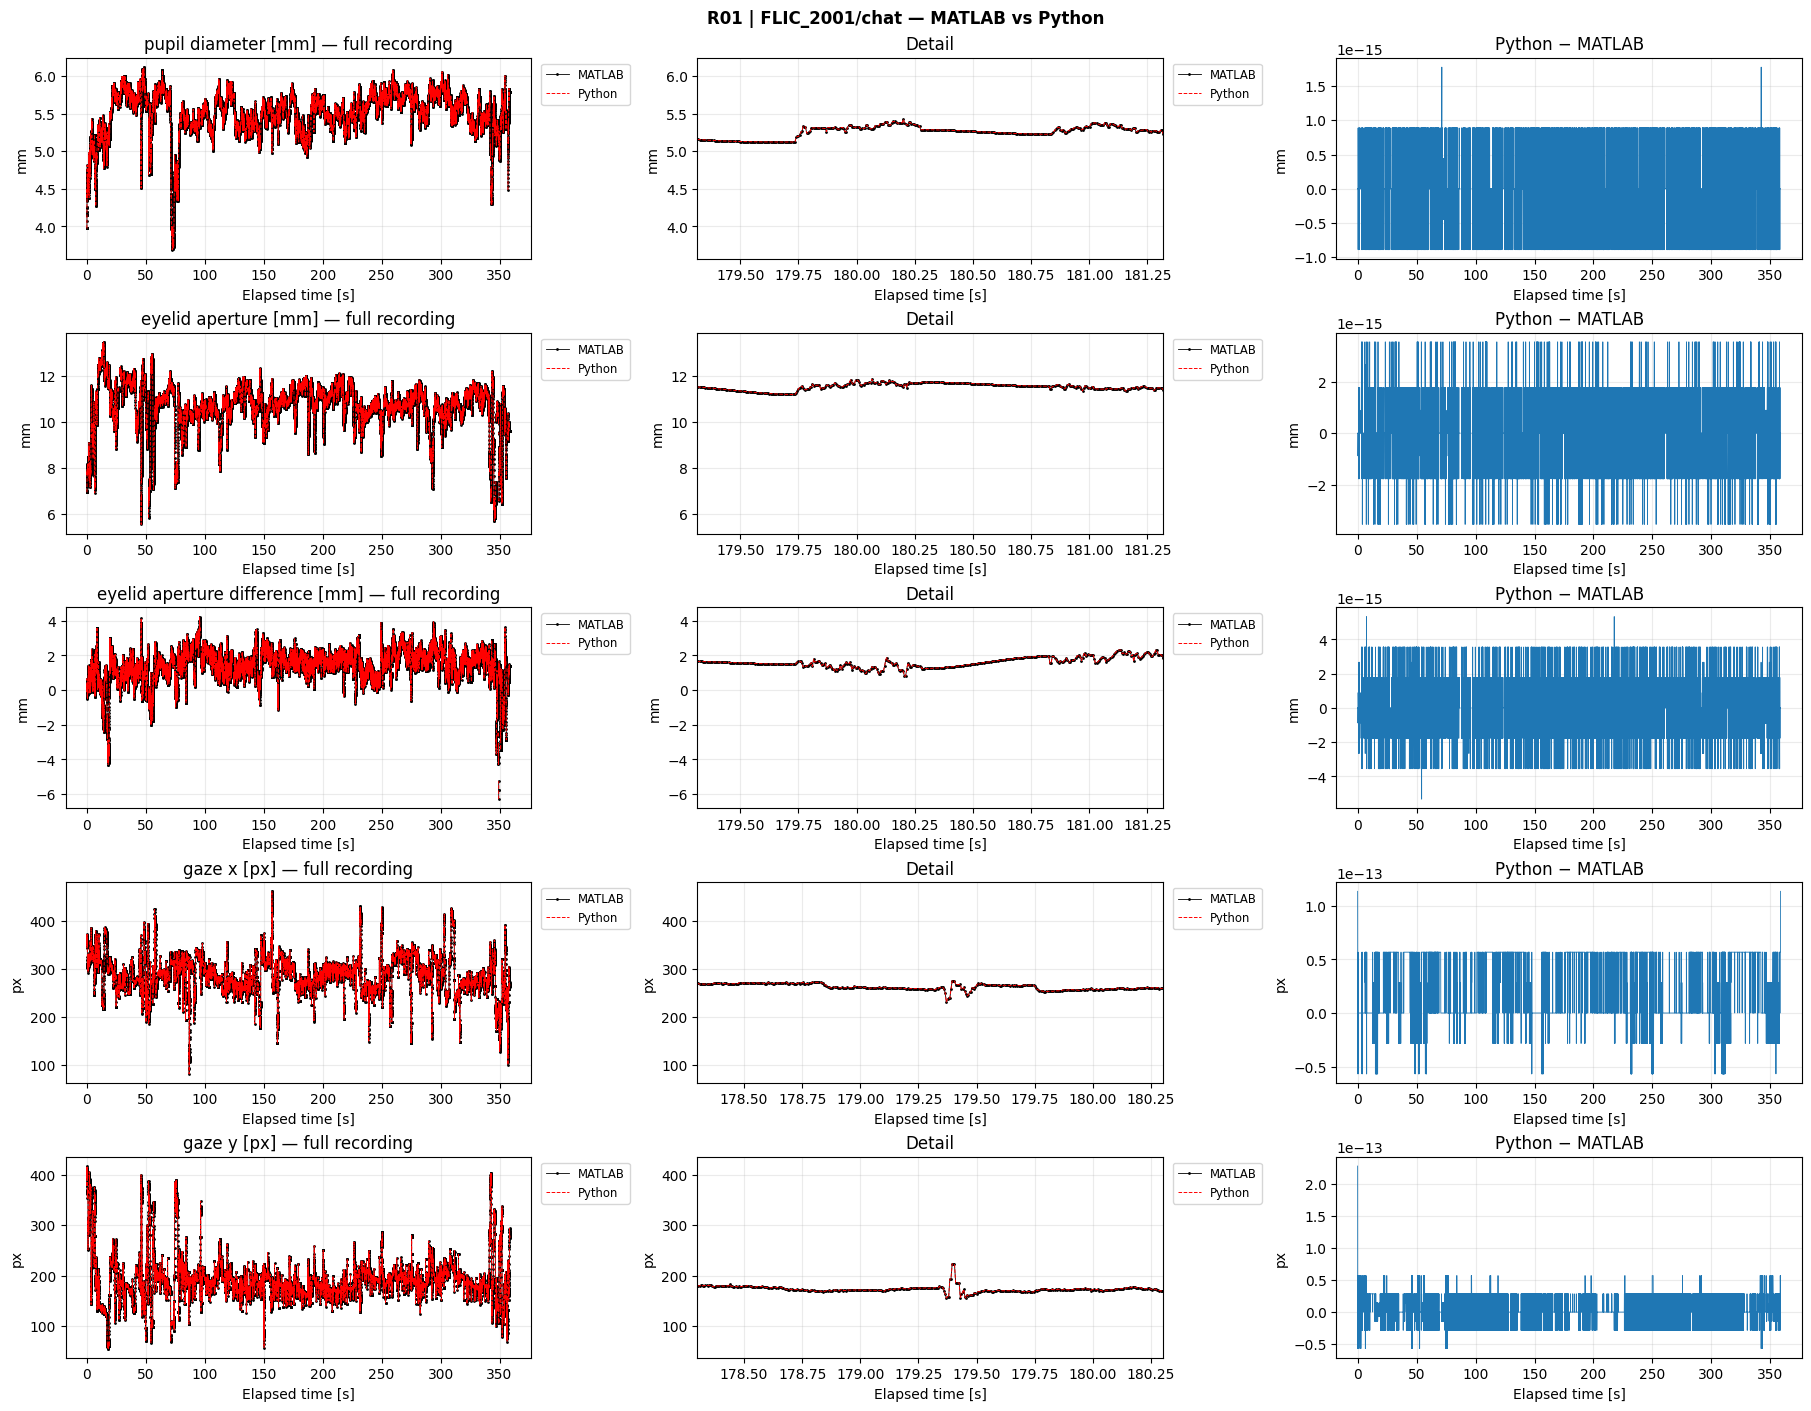

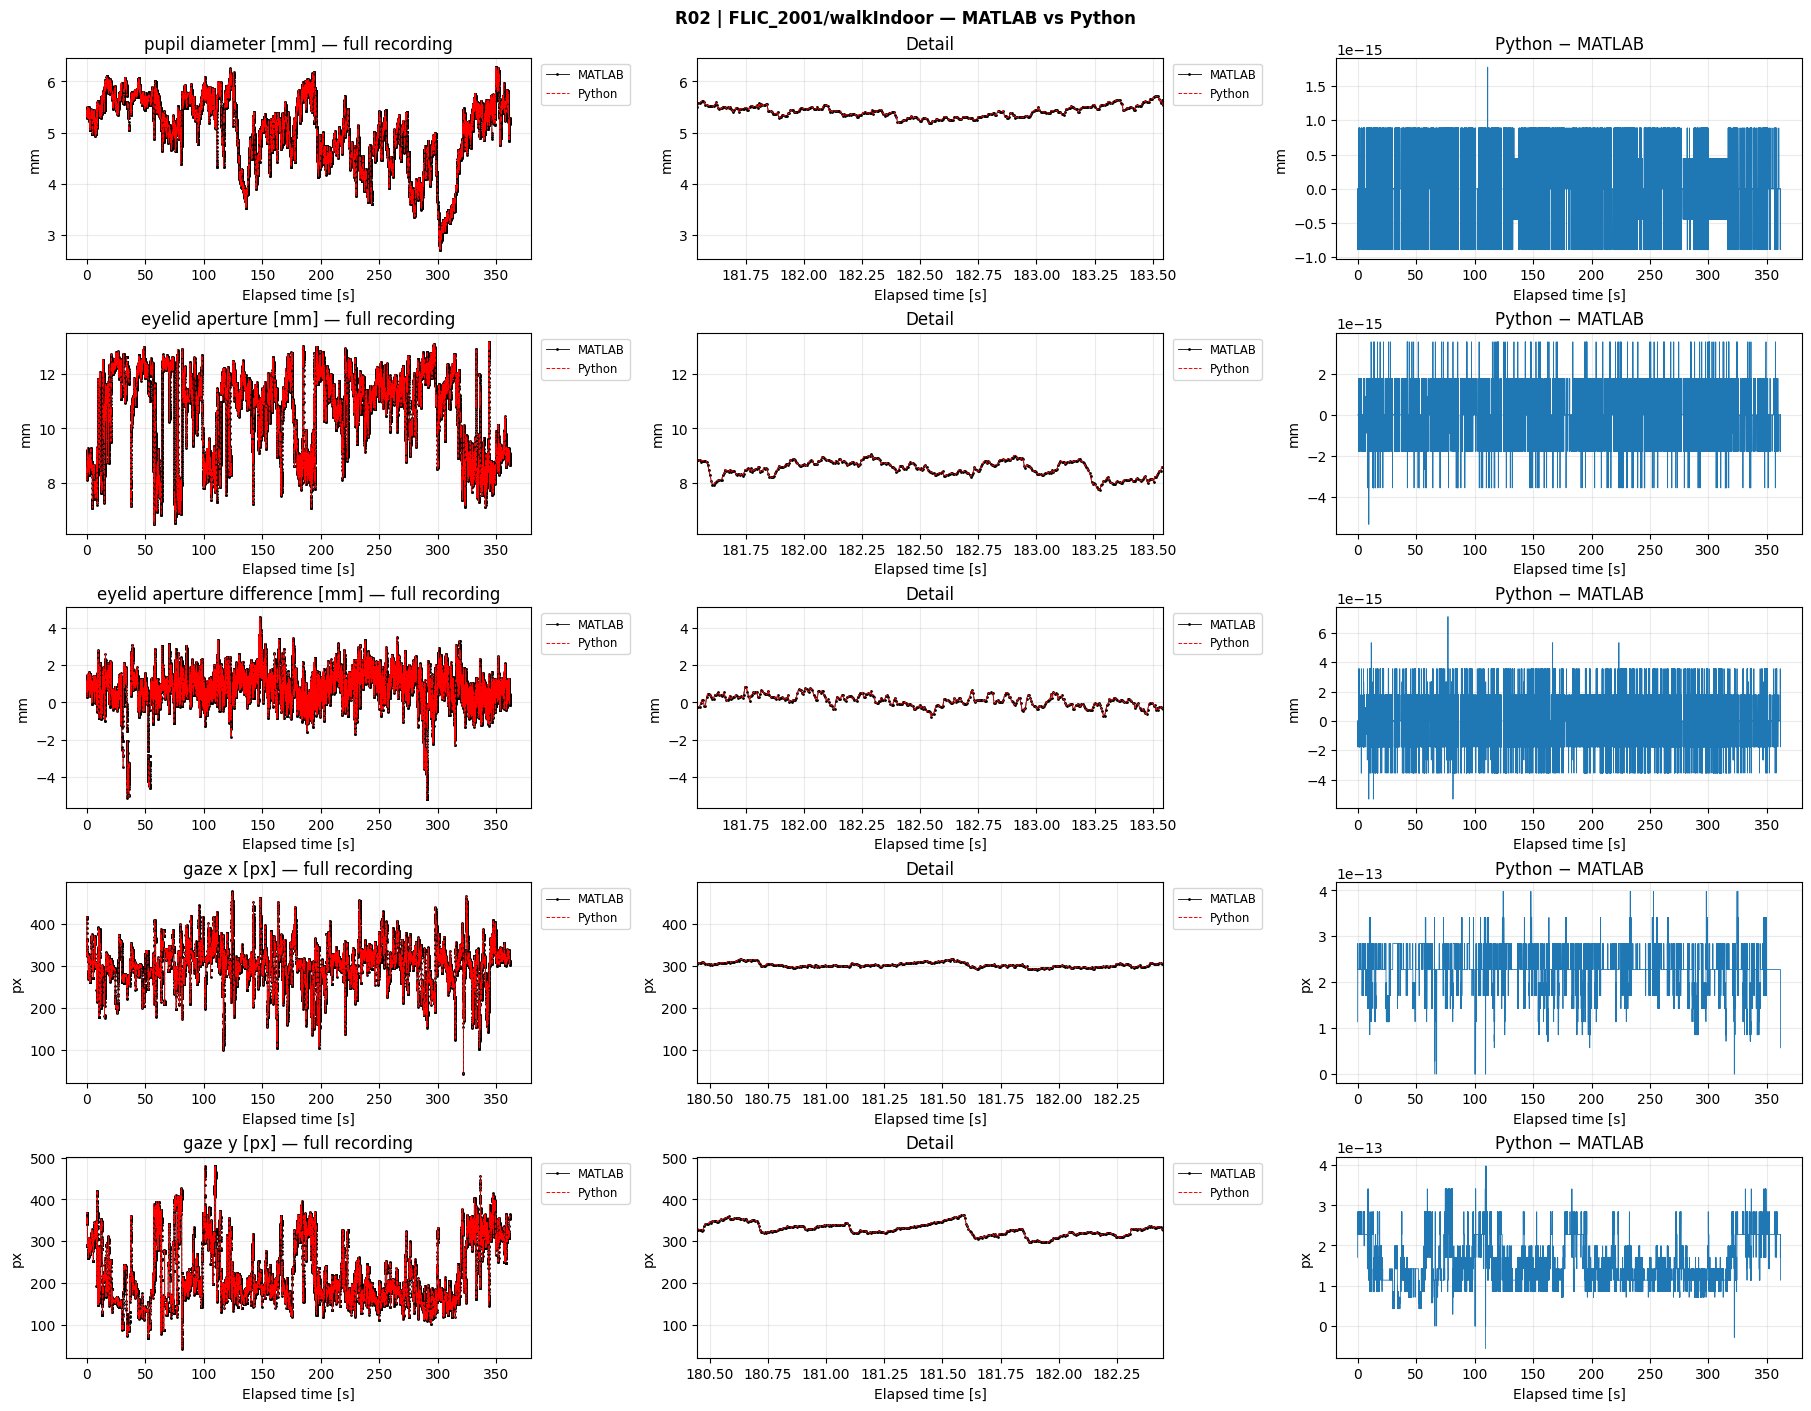

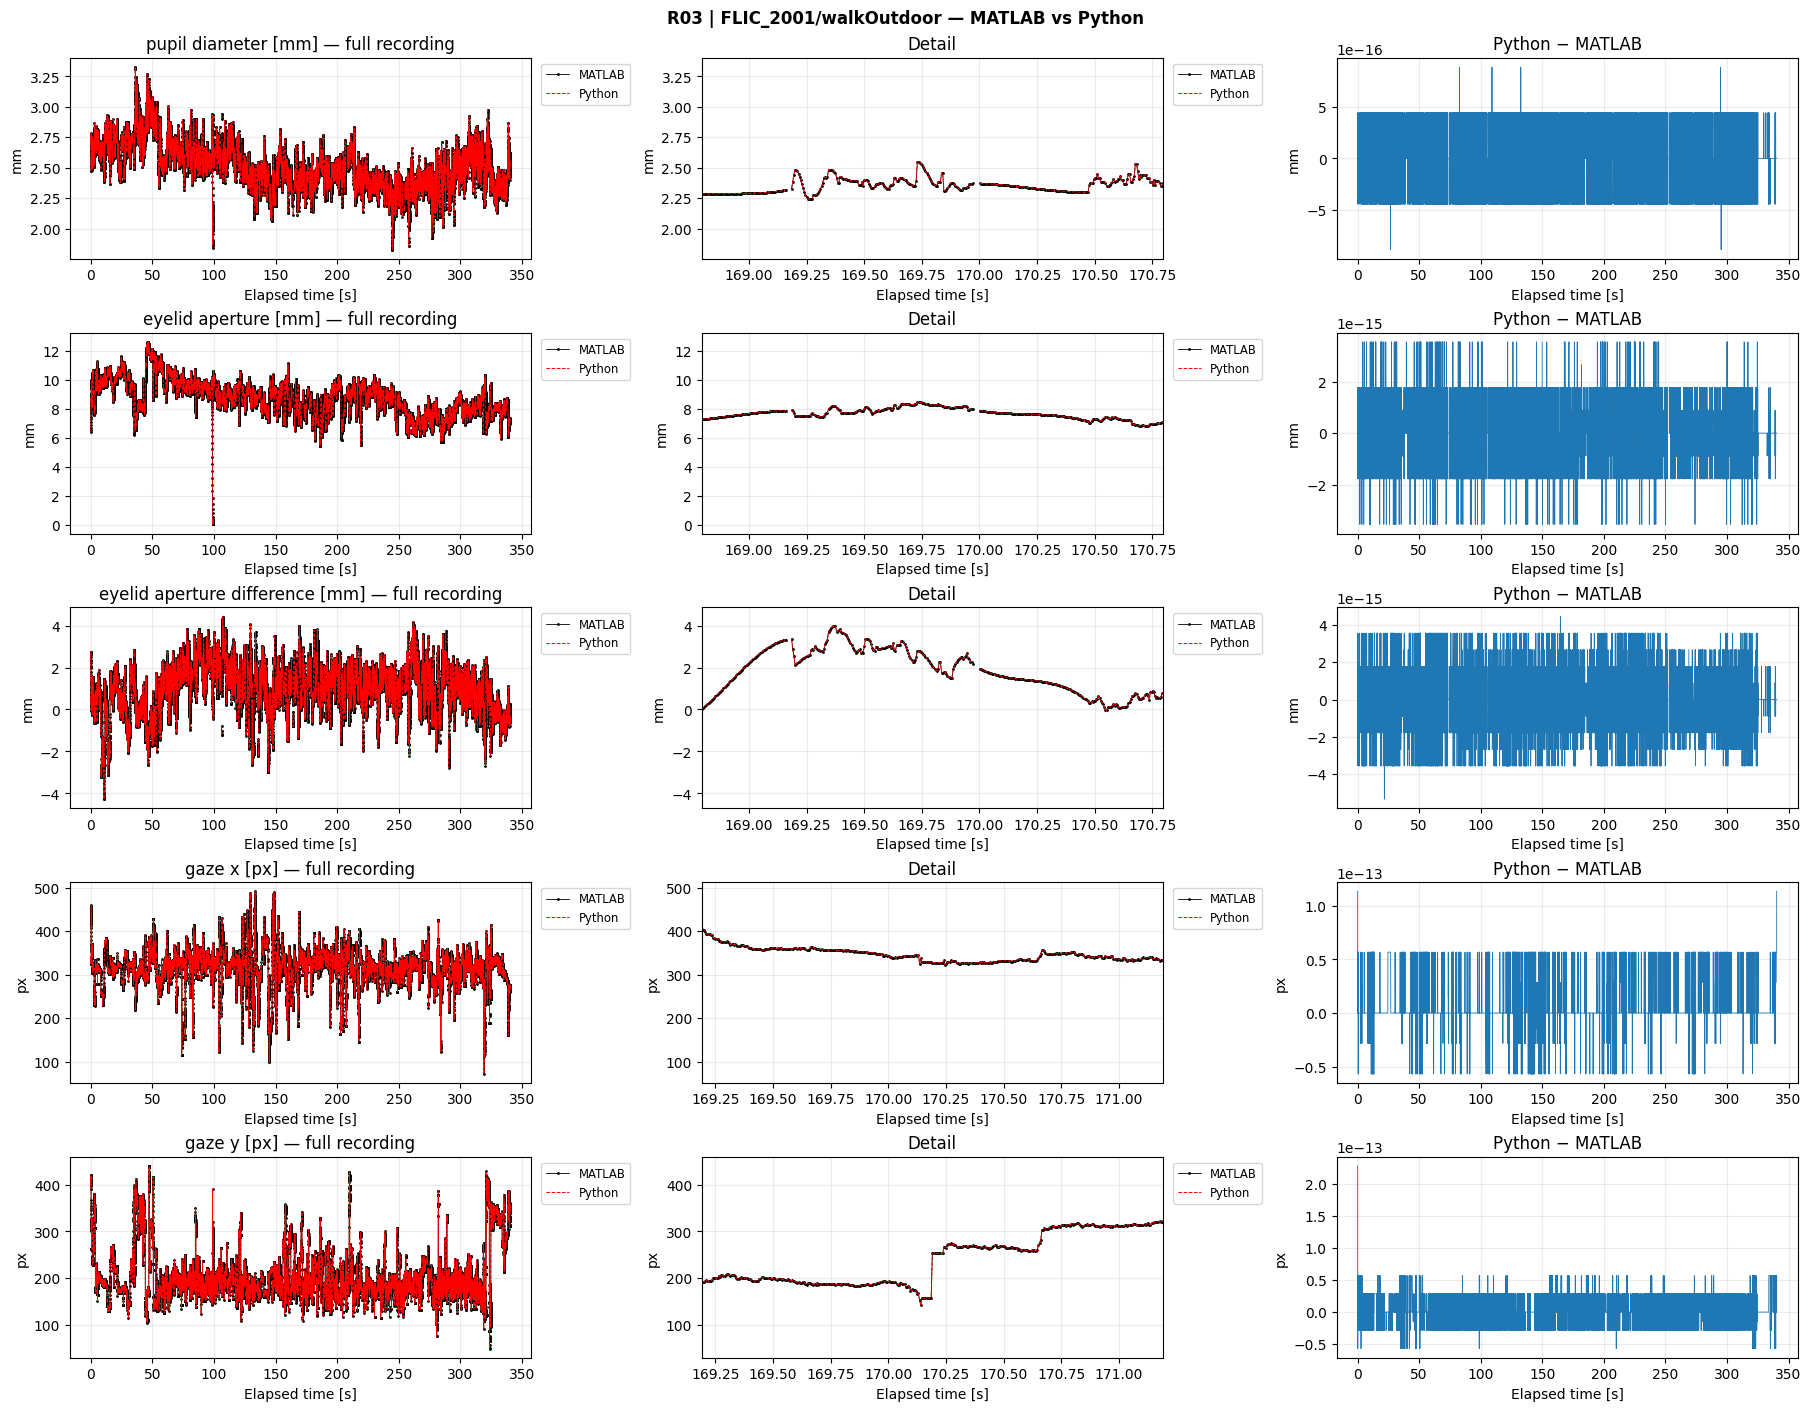

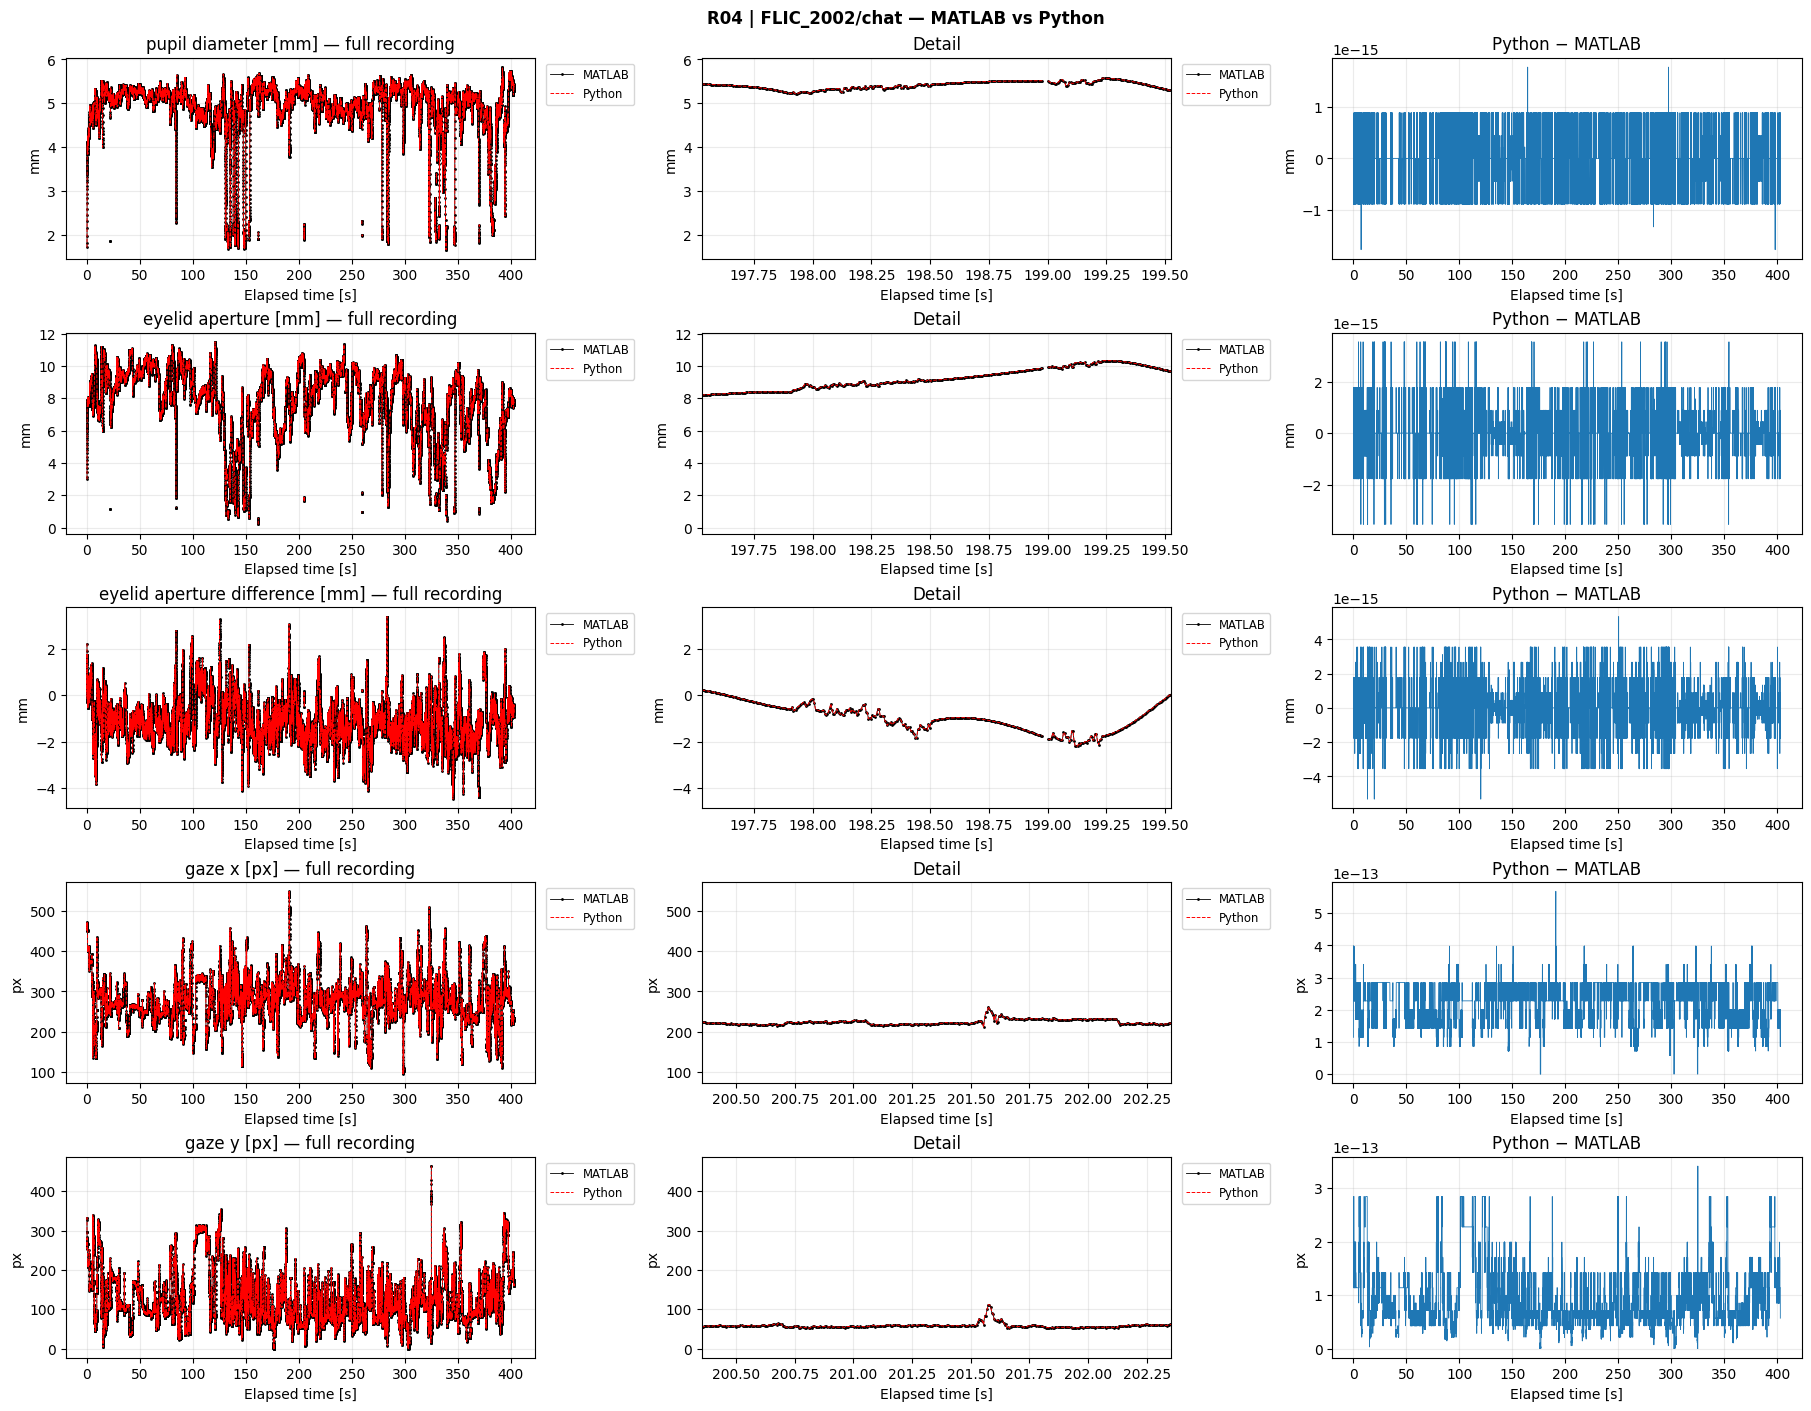

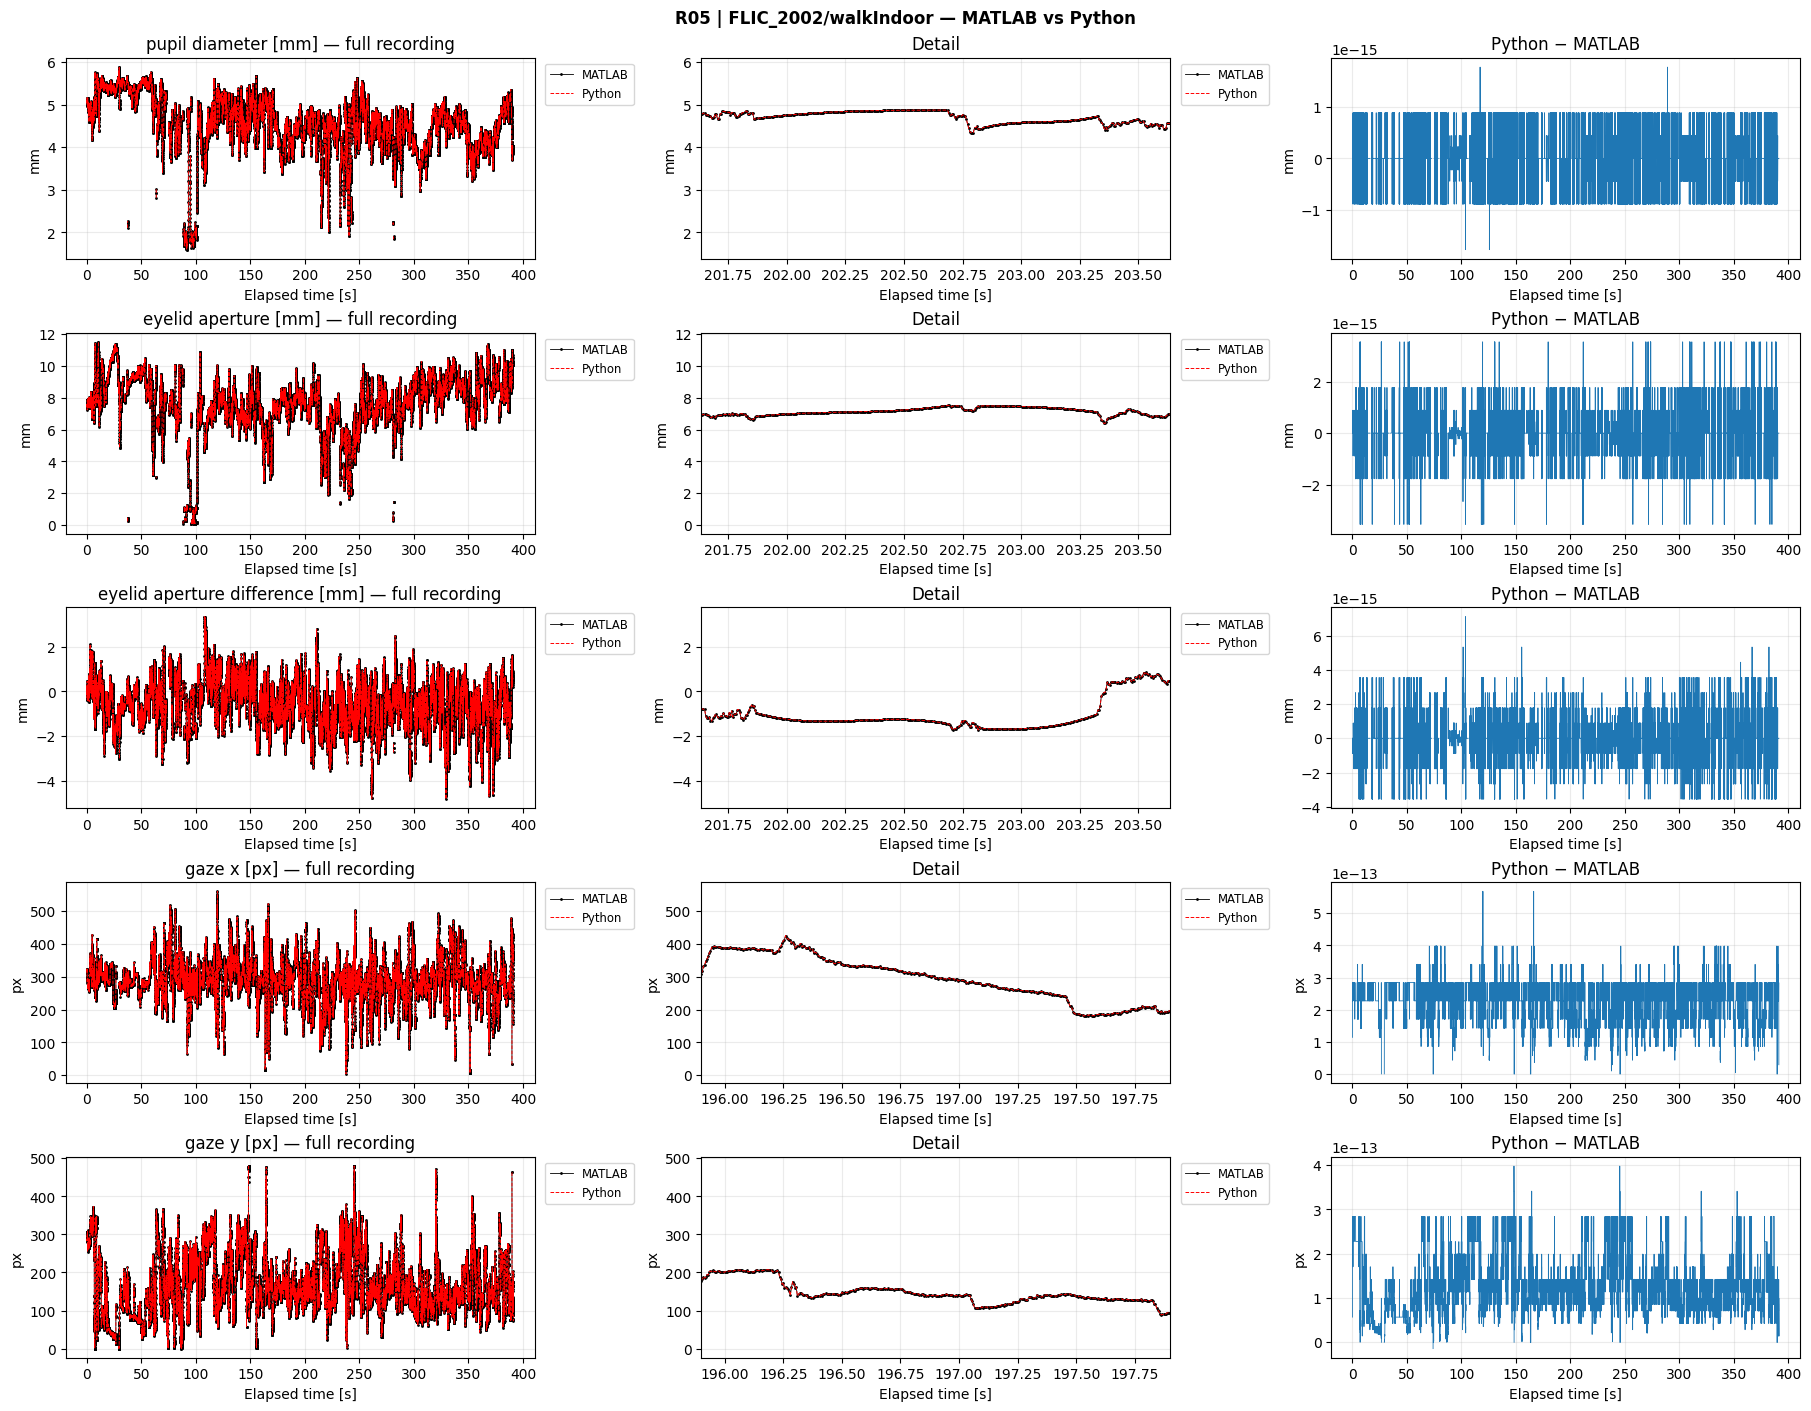

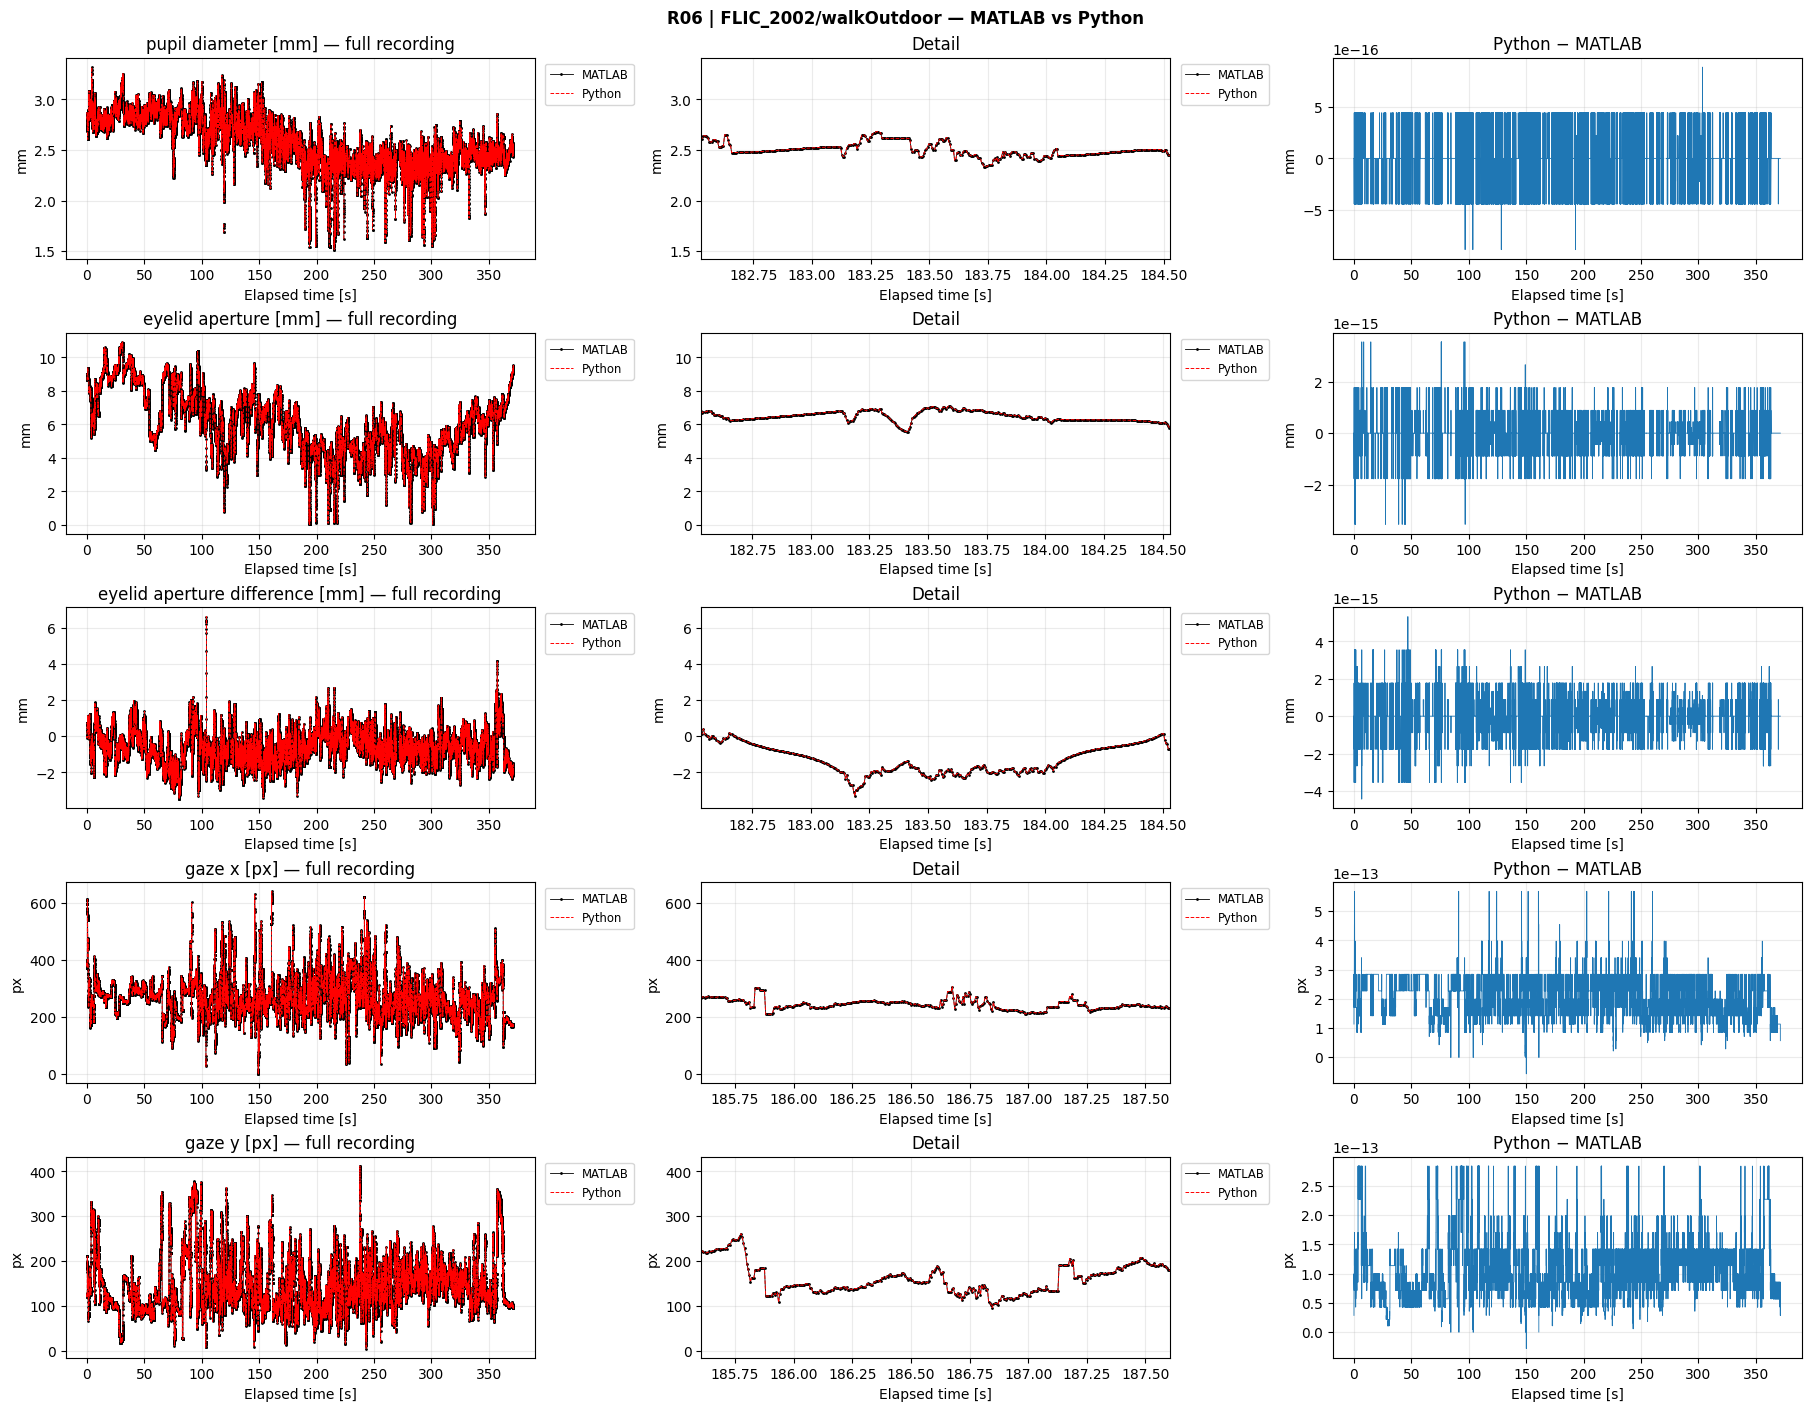

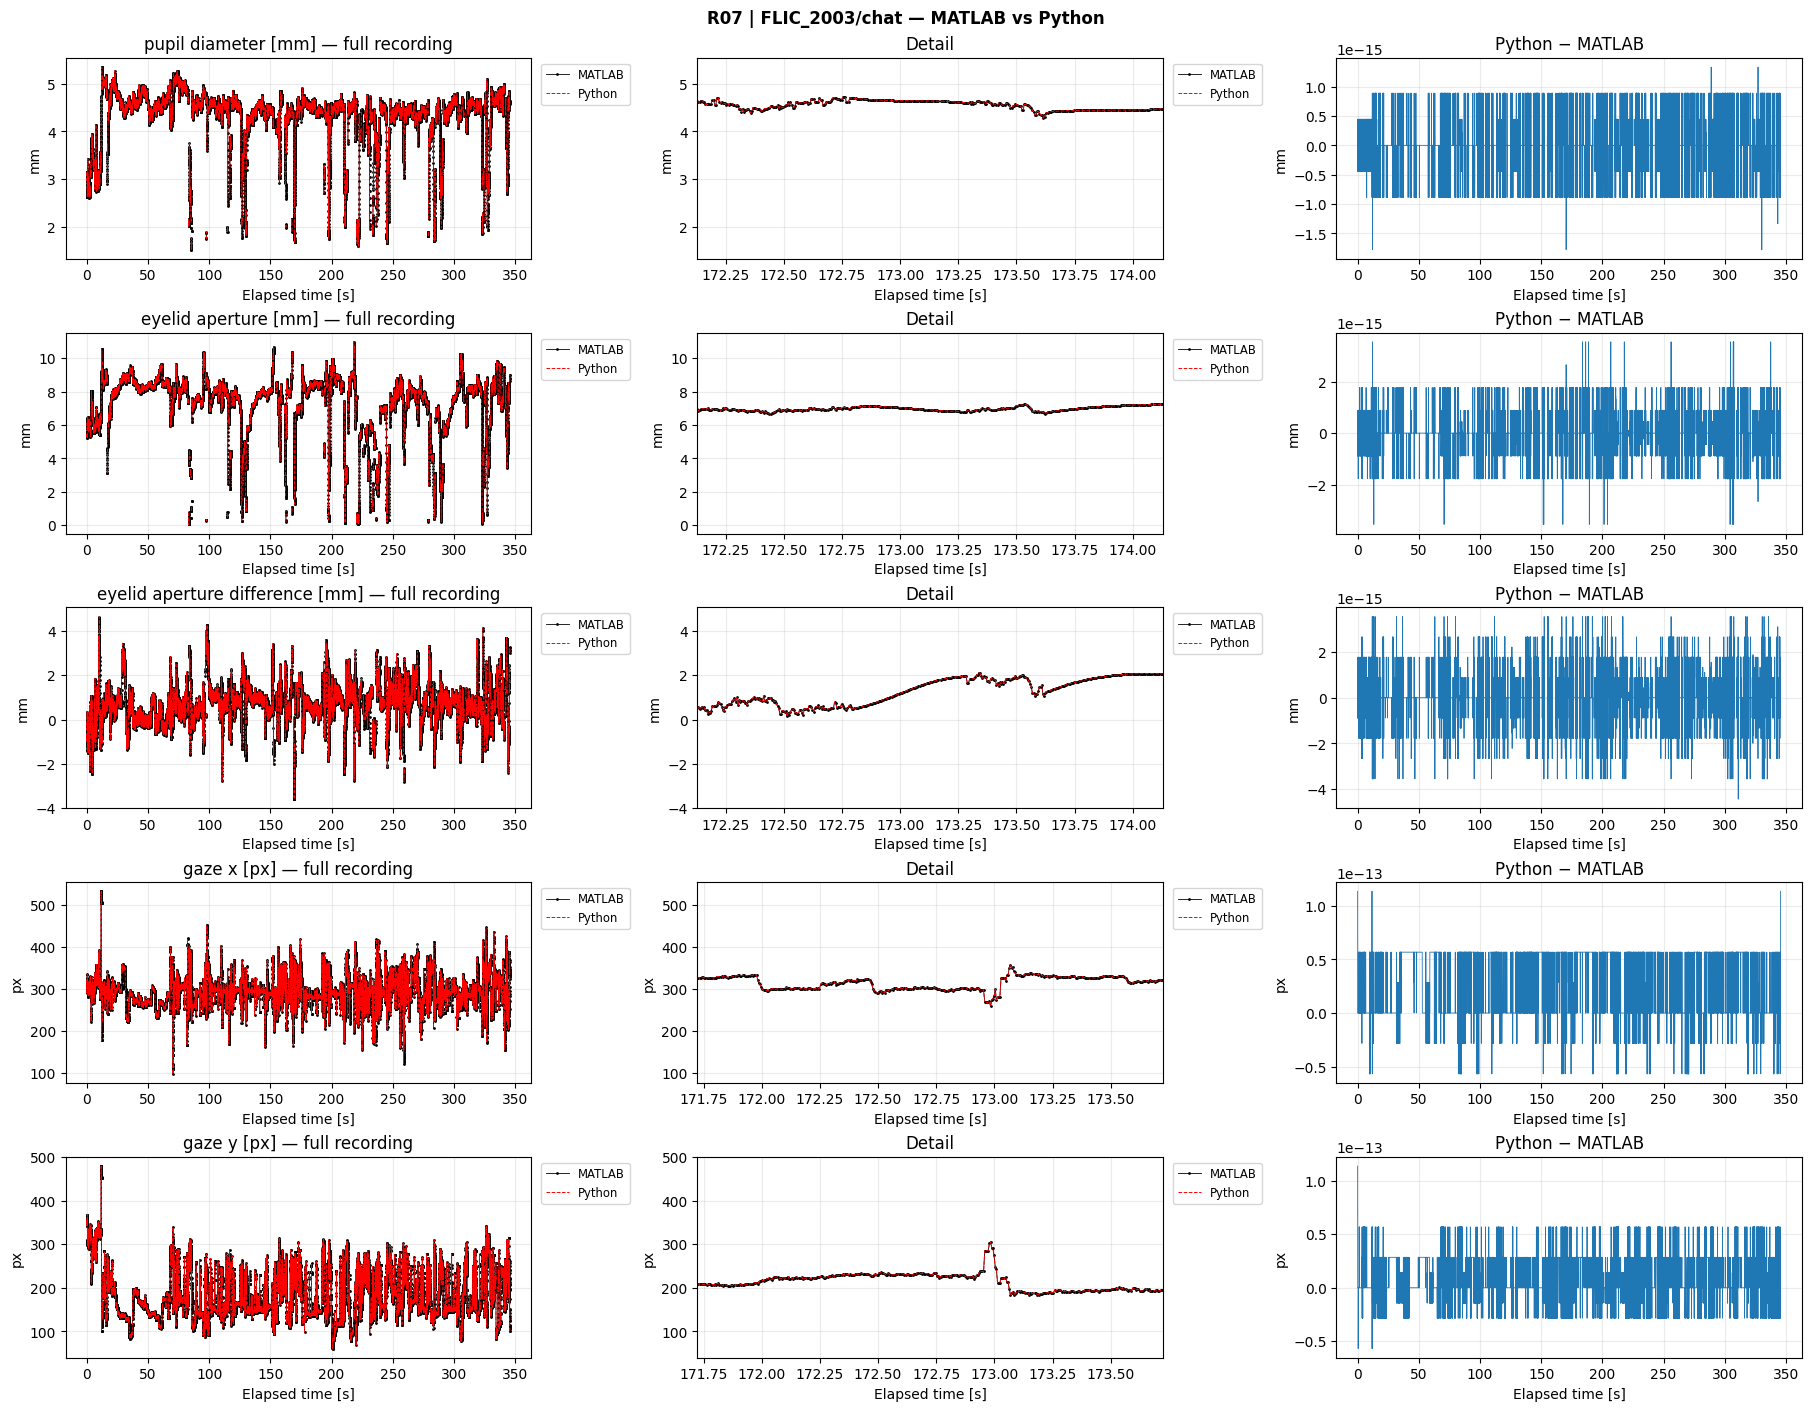

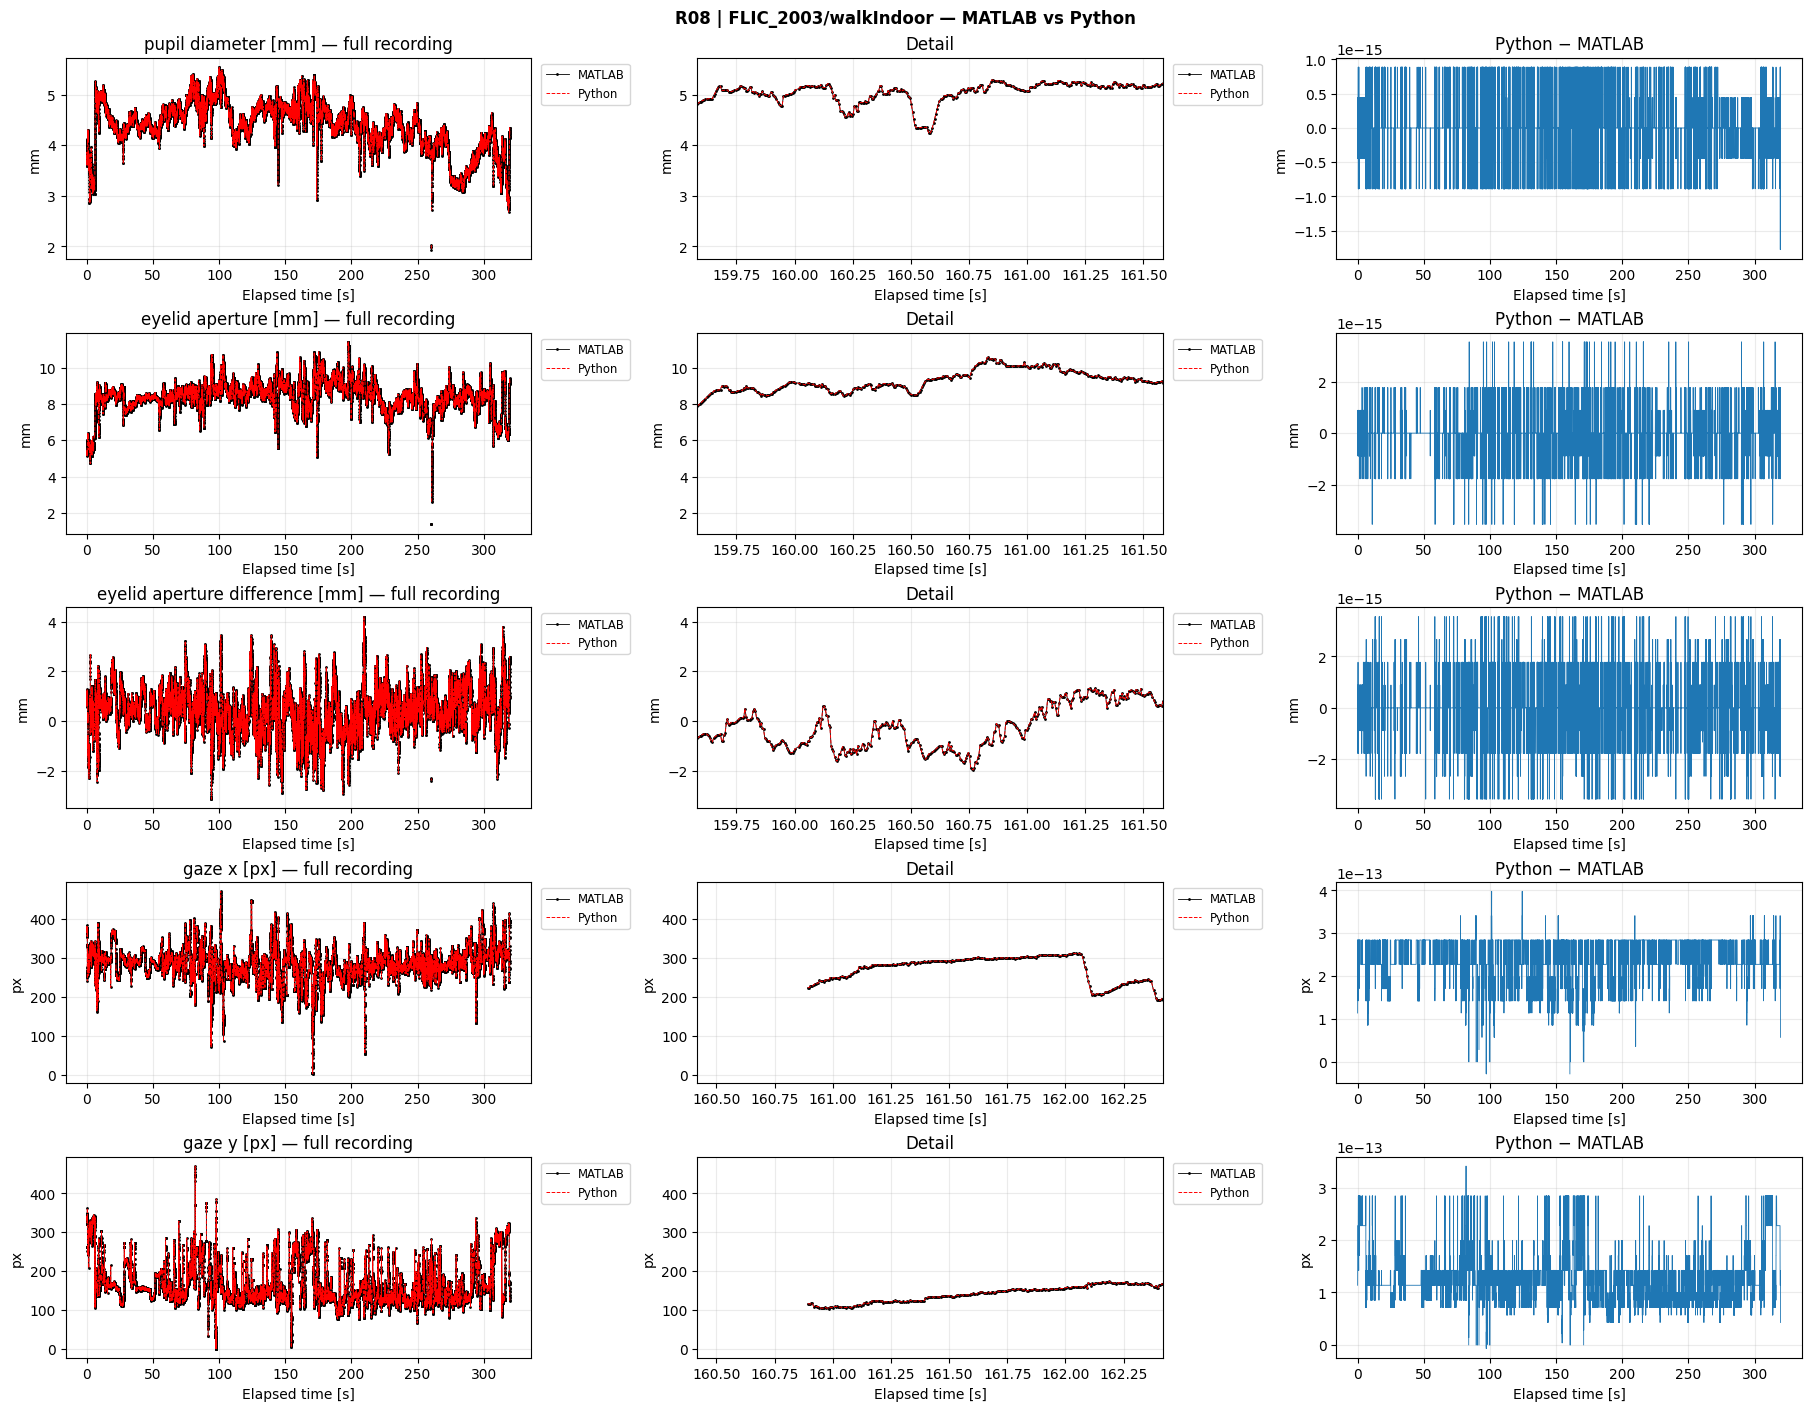

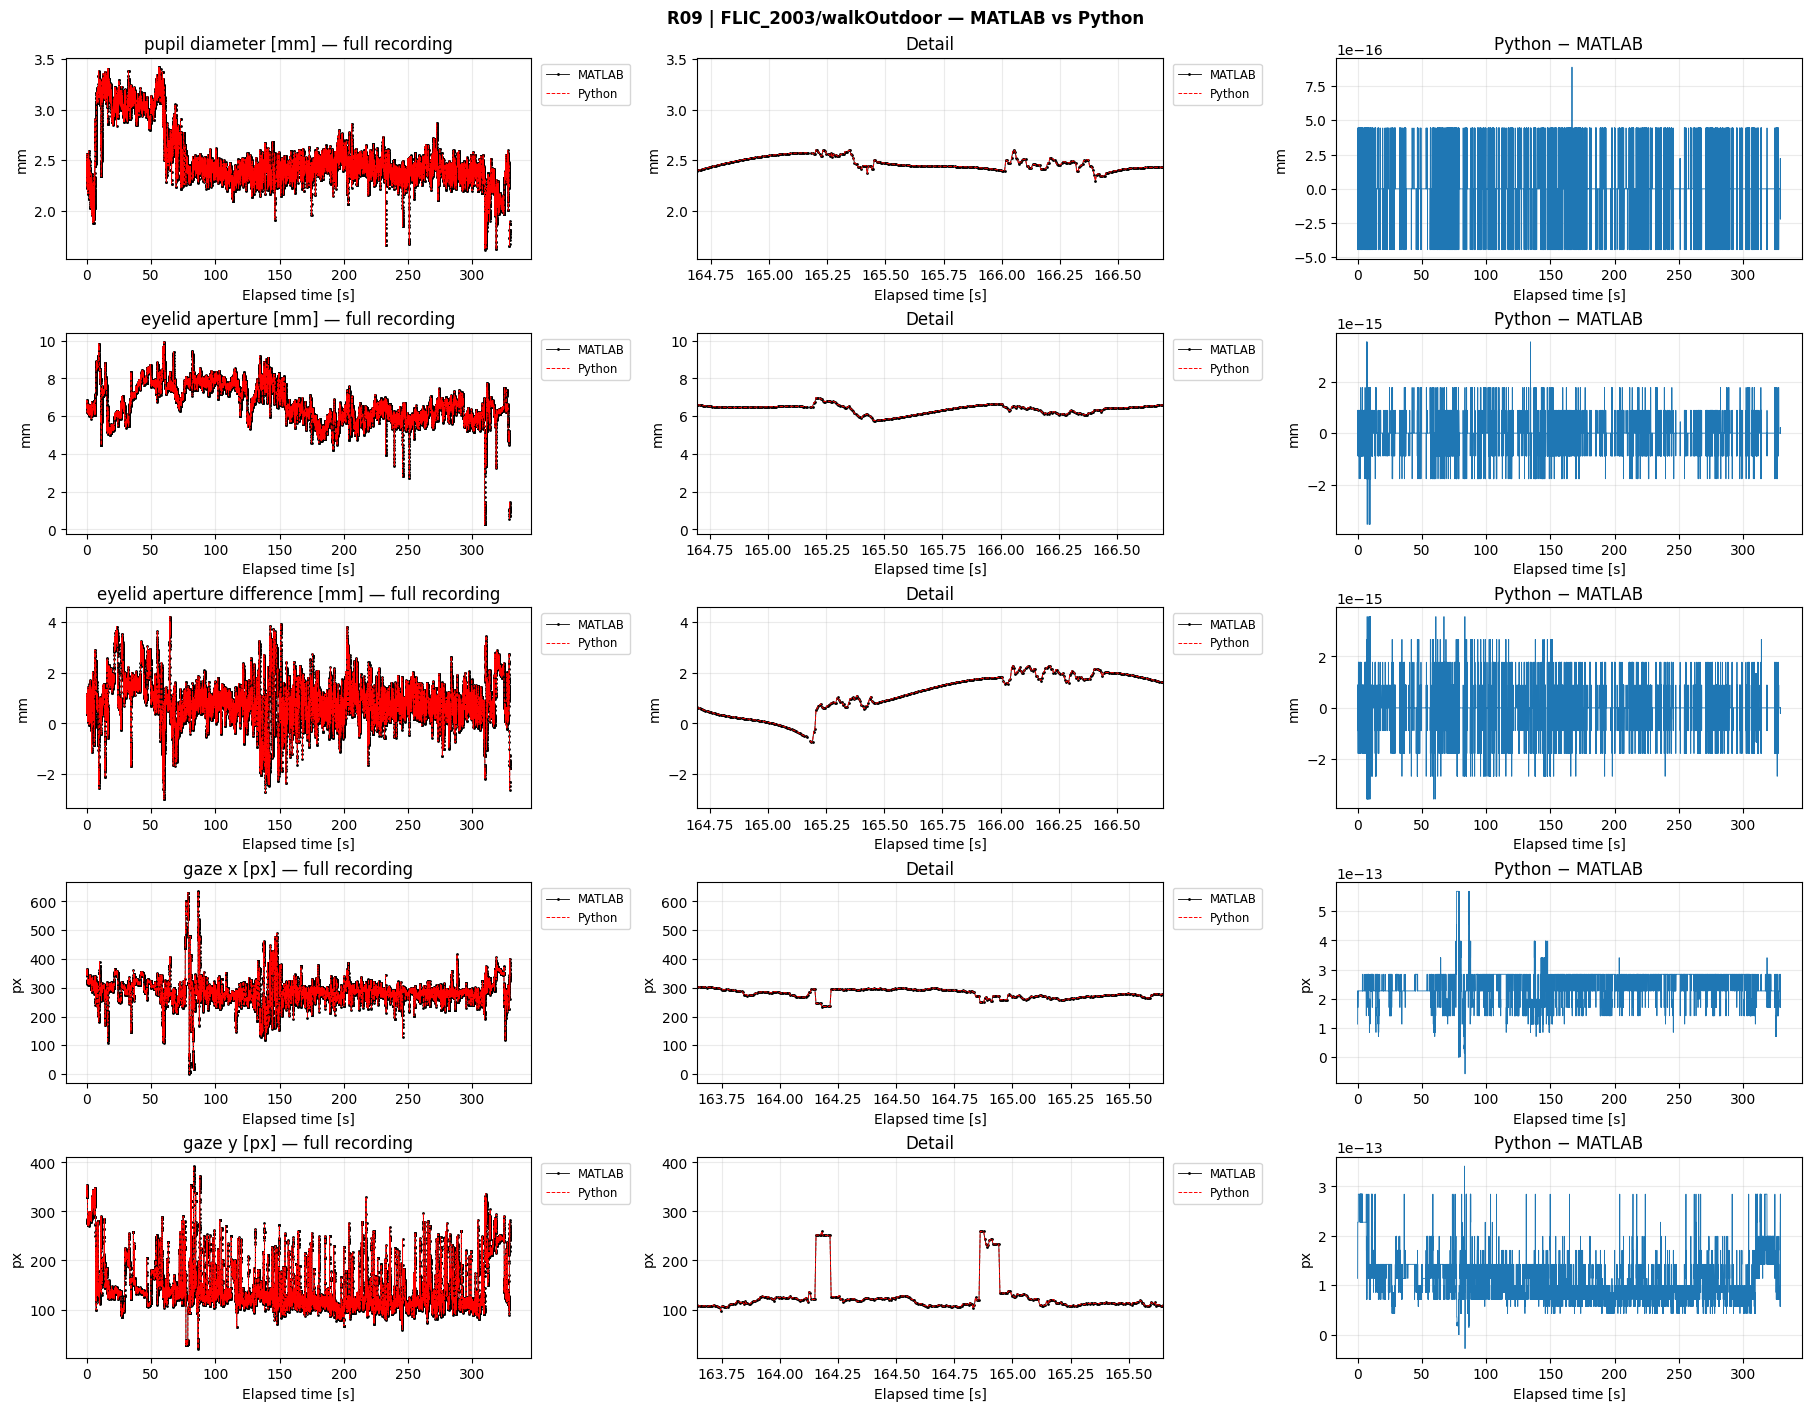

In [17]:
for case in cases:
    name = case["name"]
    reference = results[name]["MATLAB"]
    candidate = results[name]["Python"]
    time = reference[:, 0]
    figure, axes = plt.subplots(5, 3, figsize=(18, 14), constrained_layout=True, squeeze=False)
    figure.suptitle(f"{case['recording_id']} | {name} — MATLAB vs Python", fontweight="bold")
    for row, label in enumerate(python_pipeline.OUTPUT_COLUMNS[1:]):
        expected, actual = reference[:, row + 1], candidate[:, row + 1]
        error = actual - expected
        finite = np.flatnonzero(np.isfinite(error))
        if finite.size and np.max(np.abs(error[finite])) > ABSOLUTE_TOLERANCE:
            focus = finite[np.argmax(np.abs(error[finite]))]
        else:
            focus = int(finite[len(finite) // 2]) if finite.size else len(time) // 2
        half_width = min(ZOOM_SECONDS / 2, (time[-1] - time[0]) / 2) if len(time) > 1 else ZOOM_SECONDS / 2
        for axis in axes[row, :2]:
            axis.plot(time, expected, "k.-", linewidth=.6, markersize=2, label="MATLAB")
            axis.plot(time, actual, "r--", linewidth=.7, label="Python")
            axis.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize="small")
        axes[row, 0].set_title(label + " — full recording")
        axes[row, 1].set_title("Detail")
        axes[row, 1].set_xlim(time[focus] - half_width, time[focus] + half_width)
        axes[row, 2].plot(time, error, color="tab:blue", linewidth=.6)
        axes[row, 2].set_title("Python − MATLAB")
        for axis in axes[row]:
            axis.set_xlabel("Elapsed time [s]")
            axis.set_ylabel("mm" if row < 3 else "px")
            axis.grid(alpha=.25)
    display(figure)
    plt.close(figure)

## 5. Optional Python reference plots

Set `SHOW_PYTHON_PLOTS` to `True` to display the six-panel MATLAB/PDF layout for all recordings. To inspect the transformation history instead, change `PLOT_STYLE` to `"stages"`. The folder-selection UI uses the reference layout by default.


In [ ]:
SHOW_PYTHON_PLOTS = False
PLOT_STYLE = "matlab"
if SHOW_PYTHON_PLOTS:
    for case in cases:
        display(Markdown(f"### {case['recording_id']} | {case['name']}"))
        python_pipeline.clean_eye_data(str(case["raw"]), str(case["mapped"]), verbose=True,
                                       )
        plt.close("all")
